# Искусственные нейронные сети
## Перцептрон и многослойные сети

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 4. Глубокое обучение**

В этом материале мы рассмотрим, из каких частей состоит искусственная нейронная сеть, что может одиночный перцептрон и зачем нужны скрытые слои. По выполненным примерам проследим путь от четырёх простых сочетаний входов до классификации новых объектов и числового прогноза.

Это учебный файл для занятия и самостоятельного чтения. **Заданий нет.** Перед каждой кодовой ячейкой описано её назначение, после неё разобраны конструкции Python, методы и результат. Формулы и математические выводы не используются.

Все наборы небольшие, создаются внутри ноутбука и не требуют интернета или видеокарты. Сеть обучается на обычном процессоре; готовые веса и большие модели не скачиваются. Для понятных небольших примеров используем уже знакомый scikit-learn. TensorFlow, Keras и PyTorch будут отдельной темой.

### Как читать и выполнять материал

Результаты сохранены, поэтому файл можно читать без запуска Python. Для повторного выполнения выберите **Restart Kernel and Run All / «Перезапустить ядро и выполнить все ячейки»**. Ядро — процесс Python с переменными в памяти; ячейки выполняются сверху вниз, поскольку используют результаты друг друга.

Нужны Python, NumPy, Pandas, Matplotlib, scikit-learn и среда Jupyter. Установка пакетов в коде не выполняется. Версии проверенной среды выведем в начале.

Здесь изучаются **полносвязные сети прямого распространения**: информация идёт от входов через слои к ответу. Устройство функций активации, оптимизаторов и обратного распространения относится к следующей теме. В примерах для этих механизмов выбраны готовые настройки; необходимые значения параметров поясняются без разбора алгоритмов обучения. Регуляризацию, специализированные архитектуры для изображений и текста здесь не рассматриваем.

Предобработку, метрики и организацию проверки уже изучали в предыдущих файлах. Здесь пользуемся ими, но не повторяем теорию. Небольшие сравнения архитектур демонстрационные; независимого финального тестирования и подбора оптимальной сети в этом файле нет.

Подключим средства для таблиц, рисунков и готовых нейросетевых моделей. `Perceptron` нужен для простого бинарного решения, `MLPClassifier` — для многослойной классификации, `MLPRegressor` — для числового ответа. Импорт не обучает модели; это подготовка доступных инструментов.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.datasets import make_blobs, make_circles
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__)
print('scikit-learn:', sklearn.__version__)

Python: 3.13.13
NumPy: 2.4.6
Pandas: 2.3.3
Matplotlib: 3.10.9
scikit-learn: 1.8.0


**Разбор кода.**

- `import` подключает модуль или пакет. `as np`, `as pd`, `as plt` задают короткие имена NumPy, Pandas и модуля рисования Matplotlib. Точка в `matplotlib.pyplot` показывает вложенный модуль. `from ... import ...` делает перечисленные инструменты доступными непосредственно по именам; запятые разделяют элементы списка импортов.
- NumPy хранит массивы, Pandas — таблицы, Matplotlib — рисунки, scikit-learn предоставляет готовые модели. `display` из IPython показывает таблицы внутри ноутбука. Конкретные импортированные классы и функции поясняются при использовании.
- `pd.set_option(...)` настраивает вид таблиц: число видимых столбцов и знаков после точки. Это не меняет хранимые числа. Строки в кавычках — текстовые значения, `12` и `3` — целые числа.
- `plt.rcParams` содержит настройки рисунков. Квадратные скобки выбирают значение по ключу; `=` присваивает новое значение. DejaVu Sans поддерживает кириллицу, `figure.dpi` задаёт плотность изображения.
- `print(...)` выводит текст и значения. `sys.version` — строка со сведениями о Python, `split()` делит её по пробелам, `[0]` берёт первый фрагмент. Нумерация позиций начинается с нуля. `.__version__` — атрибут версии пакета.
- Точка выбирает атрибут или метод. Круглые скобки после имени выполняют вызов; внутри них передаются аргументы.

## 1. Нейрон, связь и слой

**Искусственный нейрон** — вычислительный блок. Он получает входные значения, учитывает их с обучаемыми **весами**, добавляет обучаемое **смещение** и выдаёт результат после внутреннего преобразования. Это модель обработки чисел, а не буквальная копия биологического нейрона.

Вес относится к конкретной входящей связи и определяет её вклад в обработку. Смещение позволяет сдвигать правило нейрона независимо от изменения входов. Числа весов и смещений подбираются при обучении; их начальные значения не являются готовым знанием о задаче. У скрытого нейрона величина веса сама по себе не доказывает важность исходного признака или причинное влияние.

**Слой** — группа элементов одного этапа обработки. Входной слой обозначает признаки, скрытый — промежуточные вычисления, выходной — представление ответа. В полносвязной сети каждый элемент следующего слоя получает значения всех элементов предыдущего. На схеме веса относятся к линиям, смещения — к вычислительным нейронам; сами числа для ясности не подписаны.

**Архитектуру** — количество слоёв и нейронов — задают до обучения. **Параметры** — веса и смещения — получают из данных. Одинаковая архитектура, обученная на других примерах, может иметь другие параметры и выдавать другие ответы.

Нарисуем две схемы: два входа с одним выходным нейроном и сеть с одним скрытым слоем из четырёх нейронов. Входные кружки только обозначают признаки; вычислительные нейроны находятся дальше. Создадим функцию рисования, чтобы позднее показать и реальную архитектуру обученной модели.

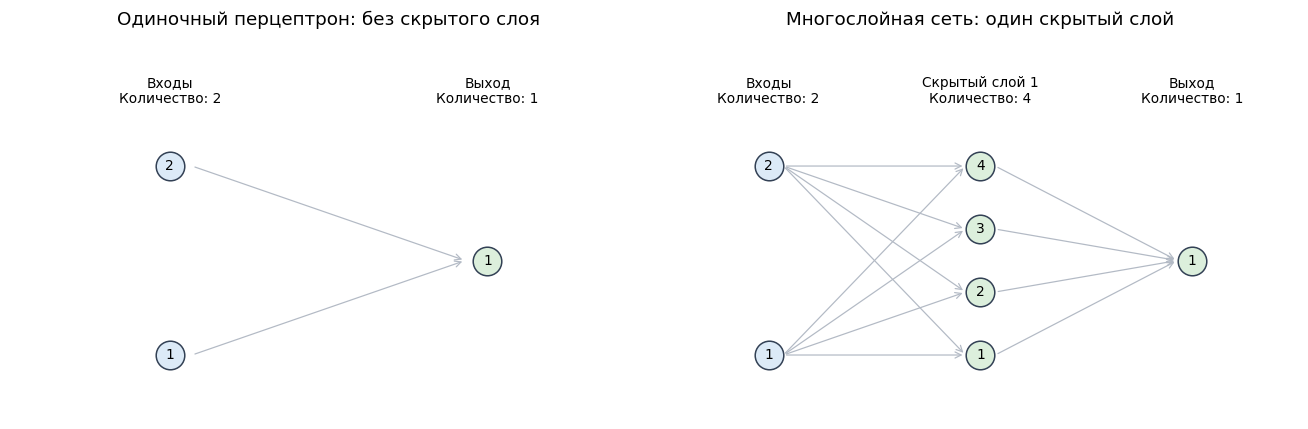

In [2]:
def draw_network(layer_sizes, ax, title):
    positions = []
    for layer_number, size in enumerate(layer_sizes):
        heights = np.linspace(0.2, 0.8, size) if size > 1 else np.array([0.5])
        positions.append([(layer_number, height) for height in heights])

    for left_layer, right_layer in zip(positions[:-1], positions[1:]):
        for x_start, y_start in left_layer:
            for x_end, y_end in right_layer:
                ax.annotate(
                    '', xy=(x_end - 0.07, y_end), xytext=(x_start + 0.07, y_start),
                    arrowprops={'arrowstyle': '->', 'color': '#b3bac5', 'lw': 0.8},
                    zorder=1,
                )

    for layer_number, layer_positions in enumerate(positions):
        color = '#dceaf7' if layer_number == 0 else '#dcefdc'
        for neuron_number, (x, y) in enumerate(layer_positions, start=1):
            ax.scatter(x, y, s=350, color=color, edgecolors='#334155', zorder=2)
            ax.text(x, y, str(neuron_number), ha='center', va='center', fontsize=9, zorder=3)
        if layer_number == 0:
            layer_title = 'Входы'
        elif layer_number == len(layer_sizes) - 1:
            layer_title = 'Выход'
        else:
            layer_title = f'Скрытый слой {layer_number}'
        ax.text(layer_number, 1.0, f'{layer_title}\nКоличество: {len(layer_positions)}', ha='center', fontsize=9)

    ax.set_xlim(-0.5, len(layer_sizes) - 0.5)
    ax.set_ylim(0, 1.15)
    ax.set_title(title, pad=20)
    ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_network([2, 1], axes[0], 'Одиночный перцептрон: без скрытого слоя')
draw_network([2, 4, 1], axes[1], 'Многослойная сеть: один скрытый слой')
fig.tight_layout()
plt.show()

**Разбор кода и схемы.**

- `def draw_network(layer_sizes, ax, title):` определяет функцию. Она получает размеры слоёв, область рисунка и заголовок. Тело с отступом выполняется при вызове; двоеточие начинает блок. Функция рисует в переданном `ax`, отдельное значение не возвращает.
- `positions = []` создаёт пустой список. `enumerate(layer_sizes)` добавляет к каждому размеру номер с нуля. Цикл `for` последовательно обрабатывает слои. `np.linspace(...)` размещает несколько кружков по высоте, `np.array([0.5])` ставит единственный кружок в середину. Выражение `... if size > 1 else ...` выбирает один из двух вариантов. `>` сравнивает числа.
- `[(layer_number, height) for height in heights]` — списковое включение: краткий цикл для создания списка координат. Пара в круглых скобках — кортеж. `.append(...)` добавляет список координат одного слоя в общий список.
- `positions[:-1]` берёт все слои, кроме последнего; `positions[1:]` — все, кроме первого. `zip(...)` объединяет соседние слои в пары. Вложенные циклы перебирают все связи между ними; запятые в `for x_start, y_start` распаковывают координаты в переменные.
- `annotate(...)` рисует стрелку: `xy` — конец, `xytext` — начало. Небольшие `+ 0.07` и `- 0.07` отодвигают стрелку от центра кружка. Словарь `arrowprops` задаёт наконечник, цвет и толщину `lw`. Пустая строка `''` означает отсутствие подписи у стрелки.
- Во второй группе циклов `scatter(...)` рисует кружки, `text(...)` — номера и подписи. `s` задаёт площадь маркера, `edgecolors` — цвет обводки, `ha` и `va` — выравнивание текста, `fontsize` — размер шрифта. `zorder` задаёт порядок наложения: кружки и номера видны поверх линий. `str(...)` превращает номер в строку.
- `if`, `elif`, `else` выбирают название слоя по его месту; `==` проверяет равенство, а `=` присваивает. `len(...)` считает элементы, `f'...'` подставляет значения в текст, `\n` переносит строку.
- `set_xlim`, `set_ylim` задают границы области; `set_title(..., pad=20)` — заголовок и отступ, `axis('off')` скрывает оси. `plt.subplots(...)` создаёт рисунок с двумя областями. `draw_network(...)` вызывается дважды; `axes[0]` и `[1]` выбирают области. `tight_layout()` размещает их, `plt.show()` выводит результат.

Стрелки показывают прямое распространение слева направо. В левой схеме входы сразу поступают в выходной нейрон. В правой выход использует результаты четырёх промежуточных нейронов. Схема пока показывает архитектуру, а не обученные параметры.

Номера в кружках показывают порядок элементов внутри слоя; в каждом слое он начинается с единицы. Сами входные значения конкретного объекта на этой схеме ещё не показаны.

## 2. Одиночный перцептрон: одно правило разделения

### Два входа и бинарный ответ

Здесь **перцептроном** называем простую модель с одним выходным нейроном для двух классов. Входы напрямую связаны с выходом; скрытых слоёв нет. При двух исходных признаках его граница решения — прямая. Числовые вклады входов подбираются во время обучения, а на выходе выбирается класс.

В качестве первого правила возьмём «класс 1, только если выполнены оба условия». Вход 1 означает «условие выполнено», 0 — «не выполнено». Это логическое **И (AND)**. У него всего четыре возможных сочетания входов, и мы покажем их все.

Такой маленький пример нужен для чтения устройства модели. Мы обучаемся на всей таблице сочетаний и проверяем воспроизведение этой же таблицы. Это **не независимая оценка качества** на новых объектах; валидацию на отдельной части введём ниже.

Создадим четыре сочетания двух условий и известный ответ AND. Таблица признаков останется общей и для следующего правила XOR, чтобы различие результатов определялось требуемой связью между входами и ответом.

In [3]:
logic_inputs = pd.DataFrame({
    'Условие А': [0, 0, 1, 1],
    'Условие Б': [0, 1, 0, 1],
})
and_target = pd.Series([0, 0, 0, 1], name='Правило AND')
display(pd.concat([logic_inputs, and_target], axis=1))

,Условие А,Условие Б,Правило AND
0,0,0,0
1,0,1,0
2,1,0,0
3,1,1,1


**Разбор кода и результата.**

- `pd.DataFrame({...})` создаёт таблицу из словаря. Ключи слева от двоеточий — имена столбцов, списки справа — значения. Квадратные скобки задают списки; одинаковые позиции в двух списках относятся к одному объекту.
- `pd.Series(..., name=...)` создаёт один именованный столбец правильных ответов. В первых трёх строках хотя бы одно условие не выполнено, поэтому ответ 0. Только строка с двумя единицами имеет ответ 1.
- `pd.concat([...], axis=1)` соединяет признаки и ответ рядом по индексам строк. `display(...)` показывает объединённую таблицу. Сами `logic_inputs` при этом не получают столбец ответа: он не должен становиться входным признаком.

Обучим готовый `Perceptron` и получим классы для четырёх сочетаний. Дополнительно выведем внутреннюю оценку решения. У перцептрона это не вероятность: отрицательные значения и значения больше единицы допустимы.

In [4]:
and_perceptron = Perceptron(max_iter=1000, tol=0.001, random_state=42)
and_perceptron.fit(logic_inputs, and_target)
and_results = logic_inputs.copy()
and_results['Правильный ответ'] = and_target
and_results['Ответ перцептрона'] = and_perceptron.predict(logic_inputs)
and_results['Внутренняя оценка'] = and_perceptron.decision_function(logic_inputs)
display(and_results)
print('Порядок классов:', and_perceptron.classes_)

,Условие А,Условие Б,Правильный ответ,Ответ перцептрона,Внутренняя оценка
0,0,0,0,0,-3.0
1,0,1,0,0,-1.0
2,1,0,0,0,-1.0
3,1,1,1,1,1.0


Порядок классов: [0 1]


**Разбор кода и результата.**

- `Perceptron(...)` создаёт ещё не обученный объект. `max_iter=1000` ограничивает число проходов обучения; `tol=0.001` задаёт допустимый порог улучшения учебного критерия для правила остановки. `random_state=42` закрепляет случайные действия обучения. Это настройки процесса, а не число входов или скрытых слоёв.
- `fit(logic_inputs, and_target)` подбирает веса и смещение по указанным признакам и ответам. `.copy()` создаёт отдельную таблицу вывода. Запись `таблица['Имя'] = ...` добавляет столбец.
- `predict(...)` выдаёт готовые классы. `decision_function(...)` возвращает внутреннюю оценку бинарного решения. `.classes_` показывает порядок кодов классов. Завершающее подчёркивание в атрибутах scikit-learn обычно обозначает состояние, появившееся после обучения.
- `display(...)` выводит таблицу, `print(...)` — порядок классов.

При порядке классов `[0, 1]` положительная внутренняя оценка выбирает класс 1; неположительная — класс 0. Масштаб этих чисел не является шкалой процентов уверенности. У `Perceptron` в используемой реализации нет метода `predict_proba`. В данном примере модель воспроизводит все четыре ответа AND.

Прочитаем выученные веса двух входов и смещение. В этой простой модели можно прямо сопоставить каждый вес с исходным условием. У многослойной сети позже появятся также связи между скрытыми нейронами, поэтому такой прямой связи с исходными полями для всех весов уже не будет.

In [5]:
display(pd.DataFrame({
    'Вход': logic_inputs.columns,
    'Вес': and_perceptron.coef_[0],
}))
print('Смещение:', and_perceptron.intercept_[0])
print('Выполнено проходов обучения:', and_perceptron.n_iter_)

,Вход,Вес
0,Условие А,2.0
1,Условие Б,2.0


Смещение: -3.0
Выполнено проходов обучения: 9


**Разбор кода и результата.**

- `.coef_` хранит веса; `[0]` выбирает единственную строку весов бинарного перцептрона. `logic_inputs.columns` содержит имена входов в соответствующем порядке. `pd.DataFrame(...)` ставит имена и веса рядом, `display(...)` выводит таблицу.
- `.intercept_[0]` читает смещение выходного нейрона. `.n_iter_` показывает фактически выполненное число проходов обучения. `print(...)` печатает значения.

Положительный вес увеличивает внутреннюю оценку класса 1 при увеличении соответствующего входа и неизменных остальных входах. Смещение сдвигает расположение границы. Конкретные числа — один из вариантов представления найденного правила; безошибочное воспроизведение четырёх строк не требует единственного возможного набора весов.

В сохранённом результате оба веса равны 2, смещение равно −3, а обучение выполнило девять проходов. Для каждого отдельного условия внутренняя оценка ещё отрицательна; положительный ответ появляется у сочетания двух выполненных условий. Эти значения описывают выученное правило текущего перцептрона.

### XOR: ограничение формы модели

Изменим только правильные ответы: класс 1 теперь нужен, когда выполнено **ровно одно** условие. Это исключающее ИЛИ, **XOR**. У сочетаний `0, 0` и `1, 1` ответ 0, у двух остальных — 1.

На плоскости пары одного класса стоят по диагонали. Одной прямой нельзя отделить оба объекта класса 1 от обоих объектов класса 0. Поэтому одиночный перцептрон с двумя такими исходными входами не может точно воспроизвести XOR. Дополнительные проходы обучения не меняют геометрическое ограничение модели. Речь именно об этих входах без дополнительных преобразованных признаков.

Создадим новый объект перцептрона и обучим его на ответах XOR. Сравним ответы построчно. Мы не ожидаем идеального результата: этот пример показывает ограничение архитектуры, а не неисправность Python или библиотеки.

In [6]:
xor_target = pd.Series([0, 1, 1, 0], name='Правило XOR')
xor_perceptron = Perceptron(max_iter=1000, tol=0.001, random_state=42)
xor_perceptron.fit(logic_inputs, xor_target)
xor_perceptron_predictions = xor_perceptron.predict(logic_inputs)

xor_results = logic_inputs.copy()
xor_results['Правило XOR'] = xor_target
xor_results['Перцептрон'] = xor_perceptron_predictions
xor_results['Совпало с правилом'] = xor_perceptron_predictions == xor_target
display(xor_results)
print('Совпало строк:', int(xor_results['Совпало с правилом'].sum()), 'из', len(logic_inputs))

,Условие А,Условие Б,Правило XOR,Перцептрон,Совпало с правилом
0,0,0,0,0,True
1,0,1,1,0,False
2,1,0,1,0,False
3,1,1,0,0,True


Совпало строк: 2 из 4


**Разбор кода и результата.**

- `pd.Series(...)` задаёт новые ответы в прежнем порядке строк. Новый `Perceptron(...)` создаётся отдельно от модели AND: параметры одной задачи не используются как уже готовое решение другой.
- `fit(...)` обучает объект на XOR, `predict(...)` возвращает его классы. `.copy()` создаёт таблицу вывода. Присваивания добавляют правильные и полученные ответы.
- `xor_perceptron_predictions == xor_target` поэлементно сравнивает ответы и создаёт логические значения `True` или `False`. `==` проверяет равенство. `.sum()` считает истинные совпадения, `int(...)` переводит результат в обычное целое число Python, `len(...)` считает строки, `print(...)` выводит итог. `display(...)` показывает подробности.

Не все строки совпадают. Остановка обучения по заданному правилу не означает, что найдены все правильные ответы. Даже другой случайный порядок или большее число проходов не позволят одной прямой точно разделить диагональные пары XOR. Теперь изменим архитектуру.

## 3. Скрытый слой: промежуточное представление

**Многослойный перцептрон (MLP)** добавляет между исходными признаками и ответом один или несколько скрытых слоёв. Первый скрытый слой обрабатывает входные признаки, следующий — уже промежуточные результаты. Выходной слой использует это представление для ответа.

Скрытый нейрон не получает отдельный правильный класс и обычно не имеет заранее заданного человеком смысла. Все веса сети подбираются совместно по общей задаче. Некоторые нейроны могут реагировать на сочетания сигналов, но нельзя автоматически назвать один из них «детектором срочности» или «важностью признака» без отдельного исследования.

Для сложной формы ответа важно не только число слоёв: внутри нейронов между слоями должно быть подходящее нелинейное преобразование. Простое увеличение числа последовательных линейных преобразований само по себе проблему XOR не решает. Подробные виды таких преобразований — функции активации — разберём в следующей теме.

Создадим MLP с одним скрытым слоем из четырёх нейронов и обучим на той же таблице XOR. Настройки внутреннего преобразования и способа подбора параметров здесь фиксированы. Посмотрим классы и оценку класса 1; сравнение относится к воспроизведению четырёх изученных строк.

In [7]:
xor_mlp = MLPClassifier(
    hidden_layer_sizes=(4,), activation='tanh', solver='lbfgs',
    max_iter=1500, random_state=42,
)
xor_mlp.fit(logic_inputs, xor_target)
mlp_xor_results = logic_inputs.copy()
mlp_xor_results['Правило XOR'] = xor_target
mlp_xor_results['Многослойная сеть'] = xor_mlp.predict(logic_inputs)
mlp_xor_results['Оценка класса 1'] = xor_mlp.predict_proba(logic_inputs)[:, 1]
display(mlp_xor_results)
print('Порядок классов:', xor_mlp.classes_)

,Условие А,Условие Б,Правило XOR,Многослойная сеть,Оценка класса 1
0,0,0,0,0,4.070e-04
1,0,1,1,1,9.996e-01
2,1,0,1,1,9.995e-01
3,1,1,0,0,3.887e-04


Порядок классов: [0 1]


**Разбор кода и результата.**

- `MLPClassifier(...)` создаёт многослойный классификатор. `hidden_layer_sizes=(4,)` задаёт **только скрытые слои**: один слой из четырёх нейронов. Вход определяется столбцами данных, выход — задачей. `(4,)` — кортеж из одного элемента; запятая нужна, потому что `(4)` было бы просто числом в скобках.
- `activation='tanh'` выбирает готовое внутреннее преобразование скрытых нейронов, `solver='lbfgs'` — готовый способ подбора параметров. Устройство этих механизмов изучается в следующей теме. Здесь используем их как фиксированные варианты библиотеки.
- `max_iter=1500` ограничивает внутренние шаги подбора для выбранного способа, `random_state=42` закрепляет случайное начальное состояние. Число шагов не является глубиной сети. Для этого `solver` шаг не следует отождествлять с полным проходом по данным, как у предыдущего перцептрона.
- `fit(...)` подбирает параметры всей сети; `predict(...)` возвращает классы. `.copy()` и присваивания готовят таблицу. `predict_proba(...)` возвращает оценки классов. Срез `[:, 1]` выбирает все строки и второй столбец; `.classes_` подтверждает, что здесь второй столбец относится к классу 1.
- `display(...)` и `print(...)` выводят результаты.

В этом выполнении сеть воспроизводит все четыре ответа XOR. Один скрытый слой уже позволил получить подходящее представление. Это демонстрация возможности архитектуры на четырёх известных сочетаниях; она не доказывает, что любая большая сеть обязательно обучится успешно на любой задаче.

В таблице Pandas использовал компактную запись маленьких чисел: `4.070e-04` означает примерно `0.000407`, а `9.996e-01` — `0.9996`. Это способ отображения чисел, а не отдельный тип ответа. Очень высокая оценка нужного класса здесь относится к четырём уже известным сети сочетаниям.

Подготовим функцию для изображения бинарных решений в пространстве двух входов. Она создаёт сетку координат, получает ответы обученной модели и закрашивает области. Правильные ответы используются только для цвета точек поверх фона и не передаются в модель при предсказании.

In [8]:
def draw_regions(model, features, labels, ax, title, margin=0.2):
    first_name, second_name = features.columns
    first_axis = np.linspace(features[first_name].min() - margin, features[first_name].max() + margin, 100)
    second_axis = np.linspace(features[second_name].min() - margin, features[second_name].max() + margin, 100)
    grid_x, grid_y = np.meshgrid(first_axis, second_axis)
    grid = pd.DataFrame({first_name: grid_x.ravel(), second_name: grid_y.ravel()})
    predicted = model.predict(grid).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, predicted, levels=[-0.5, 0.5, 1.5], colors=['#dceaf7', '#f9dedb'])
    ax.scatter(features[first_name], features[second_name], c=labels, cmap='coolwarm', vmin=0, vmax=1, s=35, edgecolors='white')
    ax.set_title(title)
    ax.set_xlabel(first_name)
    ax.set_ylabel(second_name)

print('Функция изображения бинарных решений подготовлена.')

Функция изображения бинарных решений подготовлена.


**Разбор кода.**

- `def draw_regions(...)` задаёт функцию. Параметры — модель, таблица двух признаков, известные ответы, область рисунка, заголовок и поле вокруг данных. `margin=0.2` задаёт значение по умолчанию: его можно не передавать при вызове.
- `first_name, second_name = features.columns` распределяет два имени столбцов по переменным. Квадратные скобки выбирают столбец; `min()` и `max()` находят его крайние значения. `- margin` и `+ margin` добавляют поле рисунка. `np.linspace(..., 100)` создаёт по 100 координат для каждой оси.
- `np.meshgrid(...)` делает две согласованные двумерные сетки. `.ravel()` разворачивает их в последовательности, `pd.DataFrame(...)` собирает пары координат в таблицу на 10 000 строк с нужными именами признаков.
- `predict(grid)` получает классы без обучения. `.reshape(grid_x.shape)` возвращает массиву двумерную форму сетки; `.shape` хранит размерности. `contourf(...)` закрашивает области, `levels` задаёт интервалы вокруг значений классов 0 и 1, `colors` — цвета фона.
- `scatter(...)` рисует исходные точки. `c=labels` задаёт их цвет по правильным ответам, `cmap` — палитру, `vmin=0`, `vmax=1` закрепляют соответствие цветов классам. `s` задаёт размер точек, `edgecolors='white'` — белую обводку. `set_title`, `set_xlabel`, `set_ylabel` подписывают область.
- Сейчас тело функции только определено. `print(...)` сообщает о готовности; рисование произойдёт при следующем вызове. Функция изменяет переданный рисунок и не возвращает отдельное значение.

Сравним правило AND у перцептрона, XOR у перцептрона и XOR у многослойной сети. Синие точки и фон соответствуют классу 0, красные — классу 1. Точка показывает известный ответ, фон — выбранный моделью класс в этой области; несовпадение цвета точки и фона означает ошибку на данном сочетании.

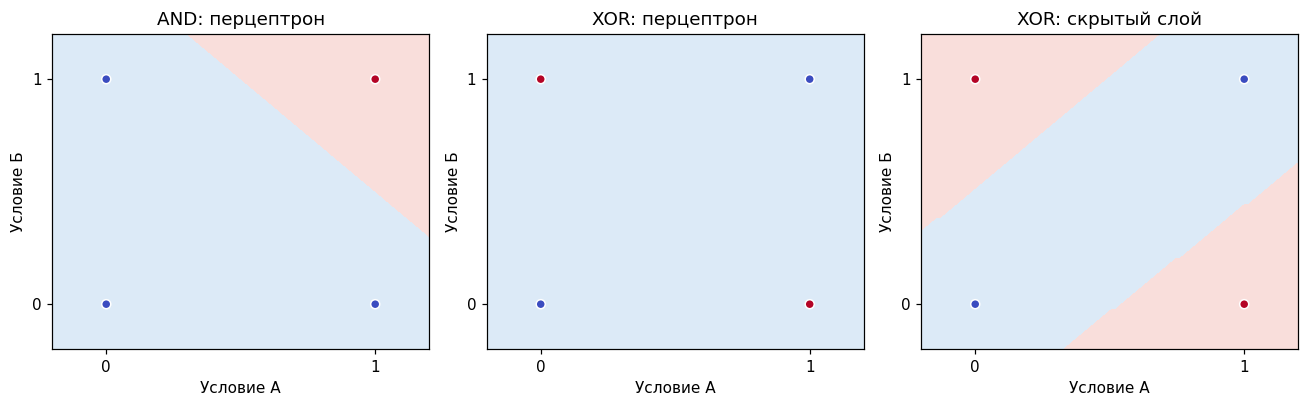

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
draw_regions(and_perceptron, logic_inputs, and_target, axes[0], 'AND: перцептрон')
draw_regions(xor_perceptron, logic_inputs, xor_target, axes[1], 'XOR: перцептрон')
draw_regions(xor_mlp, logic_inputs, xor_target, axes[2], 'XOR: скрытый слой')
for ax in axes:
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `plt.subplots(1, 3, ...)` создаёт ряд из трёх графиков. Три вызова `draw_regions(...)` получают разные пары «модель, нужный ответ», но одинаковые признаки. `axes[0]`, `[1]`, `[2]` выбирают графики по позиции.
- Цикл `for ax in axes:` применяет к каждой области одинаковые настройки. `set_xticks([0, 1])` и `set_yticks([0, 1])` оставляют на осях два значения входов. `tight_layout()` размещает графики, `plt.show()` выводит их.

Перцептрон AND отделяет нужный угол одной прямой. Для XOR одиночный перцептрон в этом выполнении выдаёт один класс на всех четырёх сочетаниях и не решает задачу. MLP создаёт нелинейное разделение и правильно отвечает в четырёх точках.

Промежуточные области на рисунке не имеют заданных логических ответов: исходное правило определено для входов 0 и 1. Поэтому цвет между четырьмя точками показывает продолжение модели, а не проверенную логическую таблицу для дробных входов.

Прочитаем размеры выученных связей и смещений сети XOR. Для каждой пары соседних слоёв библиотека хранит отдельный массив весов. По этим размерам проверим, что обученная модель действительно соответствует схеме «два входа — четыре скрытых нейрона — один выход».

In [10]:
xor_connection_rows = []
for connection_number, (weights, biases) in enumerate(zip(xor_mlp.coefs_, xor_mlp.intercepts_), start=1):
    xor_connection_rows.append({
        'Переход': connection_number,
        'Размер массива весов': str(weights.shape),
        'Весов': weights.size,
        'Смещений': biases.size,
    })
display(pd.DataFrame(xor_connection_rows).set_index('Переход'))
print('Все слои, включая вход и выход:', xor_mlp.n_layers_)
print('Выходных нейронов:', xor_mlp.n_outputs_)

,Размер массива весов,Весов,Смещений
Переход,,,
1,"(2, 4)",8,4
2,"(4, 1)",4,1


Все слои, включая вход и выход: 3
Выходных нейронов: 1


**Разбор кода и результата.**

- `xor_mlp.coefs_` — список массивов весов, `xor_mlp.intercepts_` — список массивов смещений. `zip(...)` сопоставляет их по переходу. `enumerate(..., start=1)` добавляет номер с единицы; цикл распаковывает номер и вложенную пару в переменные.
- `.shape` сообщает форму массива: сначала число элементов предыдущего слоя, затем следующего. `.size` сообщает количество чисел. `str(...)` превращает форму в текст для компактного столбца.
- `.append({...})` добавляет словарь строки в список. `pd.DataFrame(...)`, `.set_index('Переход')` и `display(...)` создают и показывают таблицу.
- `.n_layers_` включает входной слой, скрытые слои и выходной. `.n_outputs_` — число выходных нейронов в этой реализации. `print(...)` выводит их.

Получились переходы `(2, 4)` и `(4, 1)`: каждый из четырёх скрытых нейронов связан с обоими входами, а выход — со всеми четырьмя скрытыми. Для этих переходов хранятся 8 и 4 веса, а также 4 и 1 смещение. Входы не получают отдельного набора обучаемых смещений: они обозначают переданные признаки.

Бинарному `MLPClassifier` здесь достаточно одного выходного нейрона. Метод `predict_proba` при этом показывает два столбца оценок классов. Число столбцов такой таблицы и число выходных нейронов не всегда одинаково.

## 4. Многослойная сеть на отдельных обучающих и проверочных объектах

### От логической таблицы к числовым сигналам

Перейдём к 320 искусственным объектам с двумя непрерывными признаками. Два класса образуют кольца: один расположен внутри другого. Форма отличается от XOR, но ограничение одной прямой остаётся существенным.

Часть объектов выделим для валидации до обучения. Перцептрон и MLP получат одинаковые обучающие строки; масштабирование включим в `Pipeline`. Здесь изучаем возможности и структуру моделей, а не заново разбираем правила разбиения и метрики.

Создадим координаты двух шумных колец и известные ответы. Один и тот же признак во всех дальнейших таблицах будет иметь одно имя и положение. Покажем несколько обучающих строк и размеры частей; правильные валидационные ответы не передаются в `fit`.

In [11]:
circle_values, circle_labels = make_circles(n_samples=320, factor=0.45, noise=0.10, random_state=21)
circle_features = pd.DataFrame(circle_values, columns=['Сигнал 1', 'Сигнал 2'])
circle_target = pd.Series(circle_labels, name='Класс')
X_circle_train, X_circle_valid, y_circle_train, y_circle_valid = train_test_split(
    circle_features, circle_target, test_size=0.25, stratify=circle_target, random_state=15
)
display(pd.concat([X_circle_train, y_circle_train], axis=1).head())
print('Обучение:', len(X_circle_train), 'объектов; валидация:', len(X_circle_valid))

,Сигнал 1,Сигнал 2,Класс
167,-1.037,-0.357,0
173,-0.319,1.131,0
134,0.141,0.490,1
149,0.079,-0.466,1
27,-0.420,0.027,1


Обучение: 240 объектов; валидация: 80


**Разбор кода и результата.**

- `make_circles(...)` создаёт координаты и метки двух колец. `n_samples=320` задаёт число объектов, `factor=0.45` — относительный размер внутреннего кольца, `noise=0.10` — разброс координат, `random_state=21` — воспроизводимость генерации.
- `pd.DataFrame(..., columns=[...])` именует два признака, `pd.Series(..., name=...)` создаёт столбец классов. Два результата генератора распределены по двум переменным слева от `=`.
- `train_test_split(...)` согласованно разделяет признаки и ответы. Возвращаются четыре значения в указанном порядке: обучающие признаки, валидационные признаки, обучающие ответы, валидационные ответы. `test_size=0.25` выделяет четверть во вторую часть, `stratify=circle_target` сохраняет примерно одинаковые доли классов, `random_state=15` закрепляет перемешивание.
- `pd.concat(..., axis=1)` ставит признаки и ответ рядом по совпадающим индексам. `head()` показывает первые пять строк; `display(...)` выводит таблицу. `len(...)` считает строки, `print(...)` сообщает размеры.

Получились 240 объектов обучения и 80 валидации. После разбиения индексы не перенумерованы, поэтому столбцы Pandas должны соединяться по соответствующим исходным индексам. Использование меток для стратифицированного разбиения не является обучением модели по валидационным ответам.

Обучим одиночный перцептрон с масштабированием входов как простой ориентир. Масштабирование будет изучать только обучающие признаки. Новые объекты проходят через то же сохранённое преобразование, поэтому при валидации отдельный `fit` подготовки не нужен.

In [12]:
circle_perceptron = Pipeline([
    ('scale', StandardScaler()),
    ('network', Perceptron(max_iter=1000, tol=0.001, random_state=42)),
])
circle_perceptron.fit(X_circle_train, y_circle_train)
perceptron_valid_predictions = circle_perceptron.predict(X_circle_valid)
print('Accuracy валидации:', round(accuracy_score(y_circle_valid, perceptron_valid_predictions), 3))
print('F1 класса 1 на валидации:', round(f1_score(y_circle_valid, perceptron_valid_predictions, zero_division=0), 3))

Accuracy валидации: 0.5
F1 класса 1 на валидации: 0.512


**Разбор кода и результата.**

- `Pipeline([...])` получает список пар `(имя шага, объект)` и выполняет шаги по порядку. `StandardScaler()` обучает приведение числовых признаков к сопоставимому масштабу. Исходные таблицы при этом остаются отдельными объектами. Подробная теория масштабирования уже была ранее.
- `Perceptron(...)` создаёт тот же вид простой модели с прежними настройками. Имя шага `network` используется для доступа к объекту внутри последовательности.
- `fit(...)` учит подготовку и перцептрон на обучающих данных. `predict(...)` применяет оба обученных шага к валидационным признакам, не получая валидационные ответы.
- `accuracy_score(...)` и `f1_score(..., zero_division=0)` вычисляют знакомые показатели. Для кодов 0 и 1 F1 по умолчанию относится к классу 1; `zero_division=0` задаёт служебный результат в неопределённом случае. `round(..., 3)` округляет вывод, `print(...)` печатает значения.

Масштабирование не превращает прямую границу перцептрона в кольцевую. Подготовка входов и выразительность самой архитектуры — разные свойства последовательности.

В выполненном примере accuracy перцептрона равна 0,5, а F1 класса 1 — примерно 0,512. Числа относятся к 80 валидационным объектам, а не к четырём сочетаниям AND или XOR. Другой набор данных означает отдельное обучение и отдельный результат.

Обучим MLP с двумя скрытыми слоями: шесть нейронов в первом, три во втором. Входных признаков по-прежнему два. Настройки внутреннего преобразования и подбора остаются теми же, что у сети XOR, а новая архитектура задаётся кортежем размеров скрытых слоёв.

In [13]:
circle_mlp = Pipeline([
    ('scale', StandardScaler()),
    ('network', MLPClassifier(
        hidden_layer_sizes=(6, 3), activation='tanh', solver='lbfgs',
        max_iter=1500, random_state=42,
    )),
])
circle_mlp.fit(X_circle_train, y_circle_train)
mlp_valid_predictions = circle_mlp.predict(X_circle_valid)
print('Accuracy валидации:', round(accuracy_score(y_circle_valid, mlp_valid_predictions), 3))
print('F1 класса 1 на валидации:', round(f1_score(y_circle_valid, mlp_valid_predictions, zero_division=0), 3))

Accuracy валидации: 0.95
F1 класса 1 на валидации: 0.95


**Разбор кода и результата.**

- `Pipeline` соединяет `StandardScaler` и `MLPClassifier`. `hidden_layer_sizes=(6, 3)` задаёт два скрытых слоя в порядке обработки. Это не число классов и не число обучающих объектов. У обоих скрытых слоёв один выбранный вариант `activation`.
- `activation='tanh'`, `solver='lbfgs'`, `max_iter=1500`, `random_state=42` имеют прежний смысл: внутреннее преобразование, способ подбора, ограничение шагов и воспроизводимость начального состояния. Все они передаются конструктору до обучения.
- `fit(...)` подбирает сохранённое масштабирование и все веса сети по обучающей части. `predict(...)` получает валидационные классы.
- `accuracy_score(...)`, `f1_score(..., zero_division=0)`, `round(..., 3)` и `print(...)` вычисляют и показывают проверочные показатели.

Два скрытых слоя позволяют последовательно строить промежуточные представления. Сеть получает только признаки и общий правильный класс объекта; отдельного обучения первого слоя «рисовать кольцо» нет. Хороший результат в этом примере не означает, что два слоя обязательно лучше одного для любой задачи.

В сохранённом выполнении accuracy и F1 равны 0,95. Правильно классифицированы 76 из 80 валидационных объектов. Это результат конкретной сети и разбиения. Четыре ошибки остаются на объектах, которых не было в обучении.

Проверим размеры обученной сети и посчитаем все её веса и смещения. Подготовим для этого короткую функцию: она пригодится для сравнения архитектур. Количество параметров — характеристика объёма обучаемого состояния, а не готовая оценка качества.

In [14]:
def count_mlp_parameters(network):
    weight_count = sum(weights.size for weights in network.coefs_)
    bias_count = sum(biases.size for biases in network.intercepts_)
    return weight_count + bias_count

circle_network = circle_mlp.named_steps['network']
connection_rows = []
for number, (weights, biases) in enumerate(zip(circle_network.coefs_, circle_network.intercepts_), start=1):
    connection_rows.append({
        'Переход': number,
        'Форма весов': str(weights.shape),
        'Весов': weights.size,
        'Смещений': biases.size,
    })
display(pd.DataFrame(connection_rows).set_index('Переход'))
print('Входных признаков:', circle_network.n_features_in_)
print('Скрытые слои:', circle_network.hidden_layer_sizes)
print('Всего слоёв:', circle_network.n_layers_)
print('Выходных нейронов:', circle_network.n_outputs_)
print('Обучаемых параметров:', count_mlp_parameters(circle_network))

,Форма весов,Весов,Смещений
Переход,,,
1,"(2, 6)",12,6
2,"(6, 3)",18,3
3,"(3, 1)",3,1


Входных признаков: 2
Скрытые слои: (6, 3)
Всего слоёв: 4
Выходных нейронов: 1
Обучаемых параметров: 43


**Разбор кода и результата.**

- `def count_mlp_parameters(network):` задаёт функцию подсчёта. Выражение `weights.size for weights in network.coefs_` последовательно выдаёт число весов каждого перехода; `sum(...)` складывает их. Аналогично считаются смещения. `return weight_count + bias_count` возвращает общее количество. Это подсчёт хранимых чисел, а не повторное обучение.
- `.named_steps['network']` извлекает обученный MLP из `Pipeline`. `.coefs_` и `.intercepts_` читаются вместе через `zip`, `enumerate(..., start=1)` добавляет номер перехода.
- `.shape` даёт форму массива, `.size` — число элементов, `str(...)` превращает форму в текст. `.append({...})` накапливает строки; `pd.DataFrame(...)`, `.set_index(...)`, `display(...)` создают и показывают таблицу.
- `.n_features_in_` — число принятых при обучении признаков. `.hidden_layer_sizes` — заданные размеры скрытых слоёв, `.n_layers_` — число всех слоёв, `.n_outputs_` — число выходов. `count_mlp_parameters(...)` вызывает нашу функцию, `print(...)` печатает значения.

Для архитектуры «2 входа, 6 скрытых, 3 скрытых, 1 выход» получены три массива весов: `(2, 6)`, `(6, 3)`, `(3, 1)`. Всего сохраняется 43 обучаемых числа: 33 веса и 10 смещений. Масштабирование имеет своё отдельное состояние и в число параметров самой сети здесь не включено.

Построим схему уже обученной сети, взяв размеры из её атрибутов. Вход и выход добавим к списку скрытых слоёв отдельно. Схема изображает наличие связей: по толщине и цвету стрелок нельзя судить о величине их обученных весов, потому что веса в оформление не передавались.

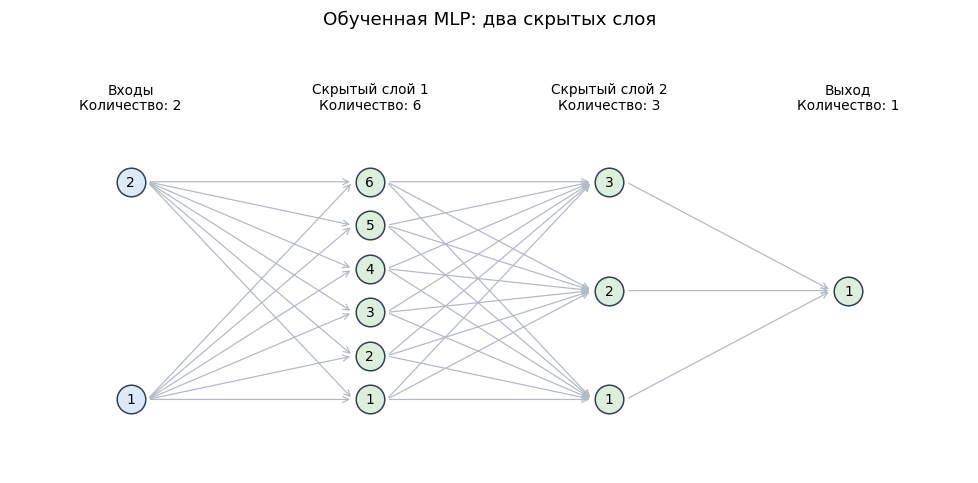

In [15]:
trained_layer_sizes = [circle_network.n_features_in_] + list(circle_network.hidden_layer_sizes) + [circle_network.n_outputs_]
fig, ax = plt.subplots(figsize=(9, 4.5))
draw_network(trained_layer_sizes, ax, 'Обученная MLP: два скрытых слоя')
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `[circle_network.n_features_in_]` — список с числом входов. `list(circle_network.hidden_layer_sizes)` превращает кортеж скрытых размеров в список. `+` соединяет списки, последний список добавляет число выходов. Получается `[2, 6, 3, 1]`.
- `plt.subplots(...)` создаёт одну область. `draw_network(...)` использует функцию из начала ноутбука, `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Нейрон второго скрытого слоя получает промежуточные ответы всех шести нейронов первого. Увеличение числа скрытых нейронов меняет число связей на соседних переходах, а не просто добавляет независимые готовые правила. Входной слой учитывается в общей схеме, но не является скрытым.

Для пяти валидационных объектов покажем классы и оценки. Одновременно проверим форму данных для одного объекта: модели передаётся таблица из одной строки и двух столбцов. При предсказании веса и смещения уже зафиксированы; мы только применяем их к входным данным.

In [16]:
binary_sample = X_circle_valid.iloc[:5]
binary_results = binary_sample.copy()
binary_results['Фактический класс'] = y_circle_valid.iloc[:5]
binary_results['Ответ сети'] = circle_mlp.predict(binary_sample)
binary_probabilities = circle_mlp.predict_proba(binary_sample)
for column_number, label in enumerate(circle_network.classes_):
    binary_results[f'Оценка класса {label}'] = binary_probabilities[:, column_number]
display(binary_results)

one_object = X_circle_valid.iloc[[0]]
print('Форма входа для одного объекта:', one_object.shape)
print('Ответ для одного объекта:', circle_mlp.predict(one_object)[0])

,Сигнал 1,Сигнал 2,Фактический класс,Ответ сети,Оценка класса 0,Оценка класса 1
102,-0.035,0.851,0,0,1.000e+00,9.410e-10
199,0.993,0.369,0,0,1.000e+00,7.068e-10
33,0.779,-0.138,0,1,2.174e-05,1.000e+00
148,0.703,-0.636,0,0,1.000e+00,2.068e-14
126,0.197,0.437,1,1,2.173e-05,1.000e+00


Форма входа для одного объекта: (1, 2)
Ответ для одного объекта: 0


**Разбор кода и результата.**

- `.iloc[:5]` выбирает первые пять строк по позиции, `.copy()` создаёт отдельную таблицу результата. Ответы Pandas присоединяются по сохранённым индексам, поэтому факт относится к нужной строке.
- `predict(...)` получает классы. `predict_proba(...)` возвращает массив оценок: строки — объекты, столбцы — классы. `.classes_` задаёт порядок столбцов, `enumerate(...)` добавляет их номера. В цикле `[:, column_number]` выбирает все строки одного столбца; `f'Оценка класса {label}'` формирует его имя. `display(...)` выводит таблицу.
- `.iloc[[0]]` выбирает одну строку **списком позиций**, сохраняя двумерную таблицу. `.shape` показывает `(1, 2)`: один объект, два признака. `.iloc[0]` без списка дало бы одномерный объект `Series`. Интерфейс модели ожидает таблицу объектов, даже если объект один.
- `predict(one_object)[0]` берёт первый и единственный класс из результата. `print(...)` выводит форму и ответ.

Один выходной нейрон бинарной сети представляет выбор между двумя классами; библиотека разворачивает его результат в два столбца оценок. Готовый класс возвращает `predict`. Оценка класса не гарантирует правильность конкретного ответа и сама по себе не является подтверждённым процентом уверенности.

Строка с индексом 33 показывает ошибку: фактический класс 0, ответ сети 1. При этом оценка класса 1 настолько высока, что в таблице округлена до `1.000e+00`, то есть отображается как 1. Это наглядный случай ошибочного ответа с высокой оценкой. Записи вроде `2.174e-05` означают очень малые числа, примерно `0.00002174`; округлённое отображение не следует принимать за точные нули или единицы исходных вычислений.

### Ширина и глубина — разные свойства

**Ширина** описывает число нейронов в слое, **глубина** — число последовательных слоёв обработки. Один широкий скрытый слой и два более узких слоя — разные архитектуры. Оба варианта могут задавать нелинейные правила, но строят промежуточное представление по-разному.

Больше параметров означает больше возможностей подстройки и больше обучаемого состояния, но не гарантирует более высокого качества. На результат влияют данные, подготовка, начальное состояние и процесс обучения. Архитектура, которую можно обучить, и архитектура, которая полезна на новых данных, не всегда совпадают.

Сравним три заранее выбранные архитектуры MLP на тех же обучающих и валидационных строках: один слой из трёх нейронов, один из восьми и уже обученную сеть с двумя слоями 6 и 3. Сеть с двумя слоями используем повторно без переобучения. Сравнение иллюстрирует размеры и результаты, а не является поиском лучшей сети.

In [17]:
mlp_variants = {}
for sizes in [(3,), (8,)]:
    variant = Pipeline([
        ('scale', StandardScaler()),
        ('network', MLPClassifier(
            hidden_layer_sizes=sizes, activation='tanh', solver='lbfgs',
            max_iter=1500, random_state=42,
        )),
    ])
    variant.fit(X_circle_train, y_circle_train)
    mlp_variants[str(sizes)] = variant
mlp_variants['(6, 3)'] = circle_mlp

architecture_rows = []
for name, model in mlp_variants.items():
    architecture_rows.append({
        'Скрытые слои': name,
        'Параметров сети': count_mlp_parameters(model.named_steps['network']),
        'F1: обучение': f1_score(y_circle_train, model.predict(X_circle_train), zero_division=0),
        'F1: валидация': f1_score(y_circle_valid, model.predict(X_circle_valid), zero_division=0),
    })
display(pd.DataFrame(architecture_rows).set_index('Скрытые слои'))

,Параметров сети,F1: обучение,F1: валидация
Скрытые слои,,,
"(3,)",13,0.835,0.830
"(8,)",33,1.000,0.937
"(6, 3)",43,1.000,0.950


**Разбор кода и результата.**

- `mlp_variants = {}` создаёт пустой словарь. Цикл перебирает два кортежа `sizes`. На каждом шаге новый `Pipeline` из `StandardScaler` и `MLPClassifier` получает текущий `hidden_layer_sizes`. Остальные параметры сохранены одинаковыми.
- `fit(...)` обучает только новые варианты. `str(sizes)` превращает кортеж в текстовый ключ словаря, `mlp_variants[...] = variant` сохраняет объект. Присваивание `mlp_variants['(6, 3)'] = circle_mlp` добавляет ссылку на уже обученную модель, не вызывая обучение.
- `.items()` выдаёт пары «ключ, объект». Во втором цикле `predict(...)` получает ответы обучения и валидации; `f1_score(..., zero_division=0)` вычисляет знакомую F1. `.named_steps['network']` выбирает MLP, `count_mlp_parameters(...)` считает его параметры.
- `.append({...})` накапливает строки. `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` формируют и показывают таблицу.

Число нейронов в одном скрытом слое и число слоёв нельзя читать как одно и то же. Например, `(8,)` означает один скрытый слой, `(6, 3)` — два. Сходные результаты на одной небольшой валидации не доказывают равенства моделей в других условиях. Эта таблица не заменяет схему выбора и независимой проверки из темы о качестве моделей.

В таблице один слой из трёх нейронов содержит 13 параметров и даёт валидационную F1 около 0,830; один слой из восьми — 33 параметра и около 0,937; два слоя 6 и 3 — 43 параметра и 0,950. У двух последних сетей F1 обучения равна 1, но валидационные ошибки остаются. Это различие между воспроизведением знакомых объектов и работой на отдельных проверочных строках.

Посмотрим на границы одиночного перцептрона и MLP с двумя скрытыми слоями. Обе модели получили те же исходные сигналы и обучающие строки. Фон отображает их ответы, цвет точек — известные обучающие классы; валидационная оценка остаётся в числовых результатах выше.

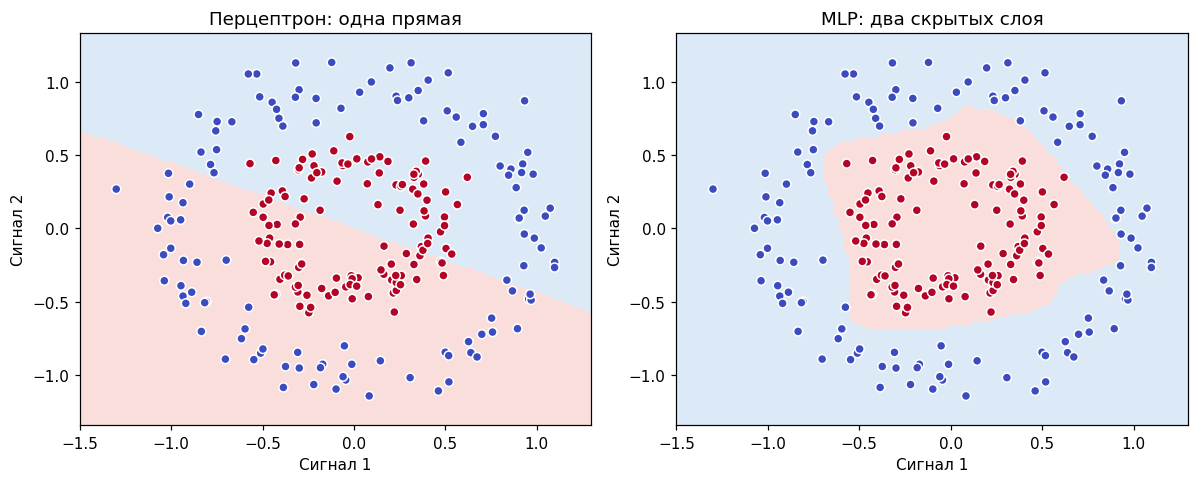

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
draw_regions(circle_perceptron, X_circle_train, y_circle_train, axes[0], 'Перцептрон: одна прямая')
draw_regions(circle_mlp, X_circle_train, y_circle_train, axes[1], 'MLP: два скрытых слоя')
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `plt.subplots(1, 2, ...)` создаёт два графика. Вызовы `draw_regions(...)` используют одну функцию с разными обученными моделями. `Pipeline` в обоих случаях сам преобразует координаты сетки сохранённым масштабированием перед предсказанием.
- `axes[0]` и `[1]` выбирают области по позиции. `tight_layout()` размещает рисунки, `plt.show()` выводит их.

Граница перцептрона остаётся прямой и не охватывает внутреннее кольцо. Сеть строит более подходящую нелинейную область. Входные признаки при этом не были вручную заменены на новые поля о расстоянии до центра: промежуточное представление получено внутри модели. Граница за областями, где есть наблюдения, показывает продолжение выученного правила и требует отдельной проверки при применении.

## 5. Выход сети зависит от задачи

### Несколько классов

Для трёх взаимоисключающих классов в используемом `MLPClassifier` выходной слой содержит три нейрона. `predict_proba` возвращает три оценки, а `predict` выбирает один класс с наибольшей оценкой. Порядок столбцов по-прежнему задаётся `classes_`.

Это отличается от рассмотренной бинарной сети с одним выходом. Входные и скрытые слои не определяют число классов сами по себе: структура выхода согласуется с типом задачи и обучающими ответами. Здесь рассматриваются обычные задачи с одним классом на объект; несколько независимых меток для одного объекта — другой сценарий.

Создадим небольшой отдельный набор с тремя известными классами и обучим MLP с одним скрытым слоем из восьми нейронов. Генератор облаков знаком по прошлому файлу, но здесь его метки используются как правильные ответы обучения с учителем. В K-Means аналогичные координаты подавались без меток — назначение данных зависит от задачи.

In [19]:
multi_values, multi_labels = make_blobs(
    n_samples=180, centers=3, n_features=2, cluster_std=1.4, random_state=35
)
multi_features = pd.DataFrame(multi_values, columns=['Сигнал А', 'Сигнал Б'])
multi_target = pd.Series(multi_labels, name='Класс')
X_multi_train, X_multi_valid, y_multi_train, y_multi_valid = train_test_split(
    multi_features, multi_target, test_size=0.25, stratify=multi_target, random_state=15
)
multi_mlp = Pipeline([
    ('scale', StandardScaler()),
    ('network', MLPClassifier(
        hidden_layer_sizes=(8,), activation='tanh', solver='lbfgs',
        max_iter=1500, random_state=42,
    )),
])
multi_mlp.fit(X_multi_train, y_multi_train)
print('Классы:', multi_mlp.named_steps['network'].classes_)
print('Accuracy валидации:', round(accuracy_score(y_multi_valid, multi_mlp.predict(X_multi_valid)), 3))

Классы: [0 1 2]
Accuracy валидации: 0.889


**Разбор кода и результата.**

- `make_blobs(...)` создаёт три облака: `n_samples` — число объектов, `centers` — число исходных облаков, `n_features` — число координат, `cluster_std` — разброс, `random_state` — воспроизводимость. Два результата — признаки и известные метки.
- `pd.DataFrame(...)` и `pd.Series(...)` именуют признаки и ответы. `train_test_split(...)` разделяет их согласованно с прежними параметрами доли, стратификации и случайного перемешивания.
- `Pipeline` объединяет `StandardScaler` и `MLPClassifier`. `(8,)` задаёт один скрытый слой; три выходных нейрона не дописываются в этот кортеж. Их число определяется тремя классами обучающих ответов при `fit(...)`.
- `.named_steps['network'].classes_` показывает классы. `predict(...)` получает валидационные ответы, `accuracy_score(...)` сравнивает их с фактами, `round(..., 3)` округляет число, `print(...)` выводит результат.

Три облака здесь содержат шум и могут перекрываться, поэтому не следует ожидать безошибочной классификации всех новых объектов только из-за видимого разделения групп.

Покажем пять валидационных объектов с тремя оценками и проверим форму последнего массива весов. Это позволит связать таблицу ответов с реальной структурой выходного слоя, а не только с названием класса модели.

In [20]:
multi_network = multi_mlp.named_steps['network']
multi_sample = X_multi_valid.iloc[:5]
multi_results = multi_sample.copy()
multi_results['Факт'] = y_multi_valid.iloc[:5]
multi_results['Ответ сети'] = multi_mlp.predict(multi_sample)
multi_probabilities = multi_mlp.predict_proba(multi_sample)
for column_number, label in enumerate(multi_network.classes_):
    multi_results[f'Оценка класса {label}'] = multi_probabilities[:, column_number]
display(multi_results)
print('Выходных нейронов:', multi_network.n_outputs_)
print('Последний массив весов:', multi_network.coefs_[-1].shape)

,Сигнал А,Сигнал Б,Факт,Ответ сети,Оценка класса 0,Оценка класса 1,Оценка класса 2
150,8.303,-8.589,2,2,8.132e-20,1.892e-26,1.000e+00
166,-7.152,-4.989,1,1,1.675e-16,1.000e+00,1.655e-32
59,6.699,-5.054,2,2,7.410e-11,2.305e-30,1.000e+00
115,6.168,-9.465,2,2,8.796e-20,1.959e-26,1.000e+00
74,-0.760,-3.517,0,0,1.000e+00,7.811e-20,2.790e-32


Выходных нейронов: 3
Последний массив весов: (8, 3)


**Разбор кода и результата.**

- `.named_steps['network']` выбирает обученную сеть. `.iloc[:5]` выбирает строки по позиции, `.copy()` создаёт таблицу вывода. Факты Pandas присоединяются с сохранением индексов.
- `predict(...)` выдаёт один класс на строку, `predict_proba(...)` — массив из трёх столбцов. `enumerate(multi_network.classes_)` сопоставляет номер столбца и код класса, срез `[:, column_number]` выбирает оценки. Строка `f'Оценка класса {label}'` именует столбец, `display(...)` показывает таблицу.
- `.n_outputs_` сообщает число выходных нейронов. `coefs_[-1]` выбирает **последний** массив из списка: отрицательный индекс `-1` отсчитывает с конца. `.shape` показывает его форму; `print(...)` выводит сведения.

Последний массив имеет форму `(8, 3)`: восемь скрытых нейронов связаны с тремя выходными. В бинарном примере было `(3, 1)` на последнем переходе сети с двумя скрытыми слоями. Правильный формат выхода нужно понимать до интерпретации отдельного столбца или номера нейрона.

### Числовой ответ

Многослойная сеть может возвращать число, а не класс. Для этого в scikit-learn используется **MLPRegressor**. При одном прогнозируемом показателе у него один выходной нейрон, но его результат интерпретируется как числовой ответ, а не оценка класса.

Сходство количества выходов с бинарной сетью не делает задачи одинаковыми. Важно, какие ответы использовались при обучении и какой вид модели выбран. У регрессора нет таблицы классов `classes_` и метода классификационных оценок `predict_proba`.

Возьмём условную нагрузку и измеренный расход ресурса. Это искусственная числовая зависимость с меняющимся темпом роста. Единицы условные; пример не описывает реальное оборудование или процесс.

Создадим 120 уровней нагрузки от 0 до 10. Зададим несколько опорных значений расхода, заполним промежутки готовой функцией NumPy и добавим небольшой шум измерений. Это только способ создать учебные данные: формулу или структуру зависимости сеть не получает.

In [21]:
rng = np.random.default_rng(27)
load_values = np.linspace(0, 10, 120)
resource_values = np.interp(
    load_values, [0, 2, 4, 6, 8, 10], [1.8, 1.9, 2.4, 4.2, 5.5, 5.7]
)
resource_features = pd.DataFrame({'Условная нагрузка': load_values})
resource_target = pd.Series(
    resource_values + rng.normal(0, 0.06, size=120), name='Расход ресурса, ед.'
)
X_resource_train, X_resource_valid, y_resource_train, y_resource_valid = train_test_split(
    resource_features, resource_target, test_size=0.25, random_state=15
)
display(pd.concat([resource_features, resource_target], axis=1).head())
print('Обучение:', len(X_resource_train), 'объектов; валидация:', len(X_resource_valid))

,Условная нагрузка,"Расход ресурса, ед."
0,0.000,1.875
1,0.084,1.851
2,0.168,1.866
3,0.252,1.748
4,0.336,1.869


Обучение: 90 объектов; валидация: 30


**Разбор кода и результата.**

- `np.random.default_rng(27)` создаёт генератор случайных чисел с фиксированным начальным значением. `np.linspace(0, 10, 120)` создаёт 120 равномерно расположенных значений, включая границы.
- `np.interp(...)` заполняет промежуточные значения между опорными точками. Первый аргумент — уровни, для которых нужен расход; второй — известные опорные уровни; третий — соответствующие им расходы. Это инструмент генерации нашего примера, а не обучение сети.
- `pd.DataFrame(...)` создаёт столбец признака. `rng.normal(0, 0.06, size=120)` создаёт небольшие случайные отклонения вокруг нуля с заданным разбросом. `+` складывает массивы по одинаковым позициям, добавляя шум. `pd.Series(..., name=...)` именует ответы.
- `train_test_split(...)` согласованно разделяет данные на обучение и валидацию. `test_size=0.25` выделяет четверть, `random_state=15` закрепляет разбиение. Стратификацию по классам не задаём: ответ непрерывный.
- `pd.concat(..., axis=1)`, `head()` и `display(...)` показывают первые строки; `len(...)` и `print(...)` — размеры частей. Получились 90 объектов обучения и 30 валидации.

Правильные ответы имеют дробные значения в условных единицах. Наличие таких значений само по себе ещё не определяет вид задачи: здесь они обозначают величину расхода, поэтому нужна регрессия.

Обучим MLPRegressor с одним скрытым слоем из восьми нейронов. Используем прежний порядок подготовки входов. Для пяти валидационных строк покажем известный расход и числовой прогноз, затем вычислим MAE в тех же условных единицах.

In [22]:
resource_mlp = Pipeline([
    ('scale', StandardScaler()),
    ('network', MLPRegressor(
        hidden_layer_sizes=(8,), activation='tanh', solver='lbfgs',
        max_iter=1500, random_state=42,
    )),
])
resource_mlp.fit(X_resource_train, y_resource_train)
resource_predictions = resource_mlp.predict(X_resource_valid)
resource_network = resource_mlp.named_steps['network']
resource_results = X_resource_valid.iloc[:5].copy()
resource_results['Фактический расход, ед.'] = y_resource_valid.iloc[:5]
resource_results['Прогноз сети, ед.'] = resource_predictions[:5]
display(resource_results)
print('MAE валидации, ед.:', round(mean_absolute_error(y_resource_valid, resource_predictions), 3))
print('Выходных нейронов:', resource_network.n_outputs_)

,Условная нагрузка,"Фактический расход, ед.","Прогноз сети, ед."
102,8.571,5.509,5.608
38,3.193,2.238,2.153
8,0.672,1.807,1.827
109,9.160,5.626,5.613
11,0.924,1.774,1.835


MAE валидации, ед.: 0.057
Выходных нейронов: 1


**Разбор кода и результата.**

- `Pipeline` объединяет `StandardScaler` и новый тип модели `MLPRegressor`. `hidden_layer_sizes=(8,)` задаёт один скрытый слой. `activation`, `solver`, `max_iter`, `random_state` имеют прежний смысл; числовой тип ответа определяется выбранным регрессором и обучающими значениями.
- `fit(...)` обучает последовательность, `predict(...)` выдаёт по одному числу на объект. `.named_steps['network']` читает обученный регрессор.
- `.iloc[:5].copy()` выбирает первые пять проверочных строк и делает отдельную таблицу. Факты Pandas добавляются по индексам; `resource_predictions[:5]` выбирает первые пять ответов массива в том же порядке. `display(...)` показывает таблицу.
- `mean_absolute_error(...)` получает все валидационные факты и прогнозы; `round(..., 3)` округляет вывод. `.n_outputs_` сообщает число выходных нейронов, `print(...)` печатает результат.

В этой задаче один выход означает прогноз расхода. Число вроде 4,2 не нужно превращать в класс 4 или ограничивать диапазоном 0–1. Сеть подстраивает числовой ответ под учебные измерения; точность оценена отдельно на валидационных объектах.

В сохранённом результате MAE составляет около 0,057 условной единицы на 30 валидационных объектах. Например, для первой показанной строки известный расход около 5,509, а ответ сети около 5,608. Числа расхода и ошибка выражены в одной условной единице, а не в процентах правильных классов.

Изобразим обучающие измерения, валидационные измерения и ответ сети на общей последовательности нагрузок. Сетка нужна для линии, а не для дополнительного обучения. По рисунку можно оценить форму найденной зависимости, но числовая оценка качества остаётся в MAE выше.

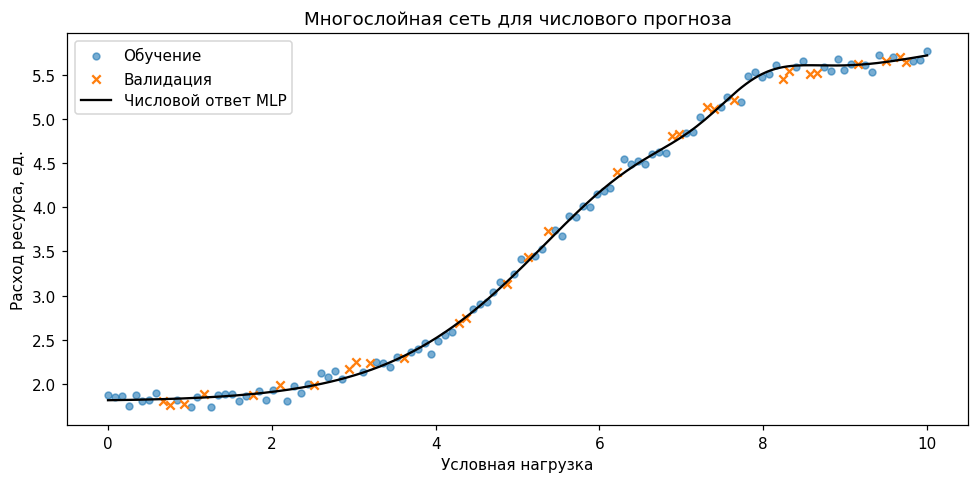

In [23]:
resource_grid = pd.DataFrame({'Условная нагрузка': np.linspace(0, 10, 200)})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(X_resource_train['Условная нагрузка'], y_resource_train, s=20, alpha=0.6, label='Обучение')
ax.scatter(X_resource_valid['Условная нагрузка'], y_resource_valid, s=30, marker='x', label='Валидация')
ax.plot(resource_grid['Условная нагрузка'], resource_mlp.predict(resource_grid), color='black', label='Числовой ответ MLP')
ax.set_xlabel('Условная нагрузка')
ax.set_ylabel('Расход ресурса, ед.')
ax.set_title('Многослойная сеть для числового прогноза')
ax.legend()
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `np.linspace(...)` создаёт 200 нагрузок, `pd.DataFrame(...)` сохраняет прежнее имя входного столбца. `plt.subplots(...)` создаёт рисунок.
- `scatter(...)` показывает точки: сначала обучающие, затем валидационные. Квадратные скобки выбирают столбец нагрузки, `s` задаёт размер, `alpha` — прозрачность, `marker='x'` — вид второй группы, `label` — текст легенды.
- `resource_mlp.predict(resource_grid)` применяет уже обученную последовательность к сетке. `plot(...)` соединяет числовые ответы линией; `color='black'` задаёт чёрный цвет. Обучение на сетке не выполняется.
- `set_xlabel`, `set_ylabel`, `set_title` задают подписи; `legend()` показывает легенду, `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Сеть с одним скрытым слоем воспроизводит меняющийся темп роста ответа. Это пример того, зачем промежуточное нелинейное представление может быть полезно и для числового прогноза. За пределами изученного диапазона нагрузок качество по этому рисунку не установлено.

## 6. Как читать архитектуру и результат вместе

Название «многослойная сеть» само по себе не описывает вход, задачу или число выходов. Нужно одновременно знать, какие признаки передаются, сколько скрытых слоёв задано и что означает ответ. Подсчёт слоёв также зависит от соглашения: атрибут `n_layers_` в использованном scikit-learn включает входной слой. При описании модели полезно явно перечислять скрытые размеры, чтобы избежать неоднозначности.

Соберём структуры четырёх уже обученных MLP в одну таблицу. Ничего дополнительно обучать не будем: прочитаем атрибуты объектов и вызовем нашу функцию подсчёта параметров. Сравниваются устройство и формат ответа, а не качество разных задач по одному числу.

In [24]:
network_catalog = {
    'XOR: два класса': xor_mlp,
    'Кольца: два класса': circle_network,
    'Облака: три класса': multi_network,
    'Числовой расход': resource_network,
}
catalog_rows = []
for name, network in network_catalog.items():
    catalog_rows.append({
        'Пример': name,
        'Входов': network.n_features_in_,
        'Скрытые слои': str(network.hidden_layer_sizes),
        'Выходных нейронов': network.n_outputs_,
        'Параметров сети': count_mlp_parameters(network),
    })
display(pd.DataFrame(catalog_rows).set_index('Пример'))

,Входов,Скрытые слои,Выходных нейронов,Параметров сети
Пример,,,,
XOR: два класса,2,"(4,)",1,17
Кольца: два класса,2,"(6, 3)",1,43
Облака: три класса,2,"(8,)",3,51
Числовой расход,1,"(8,)",1,25


**Разбор кода и результата.**

- `network_catalog` — словарь с названиями и **обученными объектами самих сетей**. Для моделей с `Pipeline` их шаги уже извлечены в отдельных переменных. Создание словаря не обучает и не копирует сети.
- `.items()` выдаёт пары «название, объект». Цикл `for name, network in ...` читает атрибуты очередной модели: `.n_features_in_`, `.hidden_layer_sizes`, `.n_outputs_`. `str(...)` превращает размеры скрытых слоёв в текст.
- `count_mlp_parameters(...)` считает веса и смещения нашей функцией. `.append({...})` добавляет строку в список, `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` показывают сводку.

В бинарных примерах один выход разворачивается библиотекой в две оценки классов. У трёх классов три выхода, у одного числового показателя один выход с другим смыслом. Количество параметров разных задач не является общей шкалой качества: данные и требуемые ответы здесь различаются.

### Опорные понятия

| Понятие | Как понимать в рассмотренных примерах |
|---|---|
| Входной признак | Одно число о конкретном объекте; столбец таблицы |
| Вес | Обучаемый параметр одной связи между входом и нейроном или между нейронами |
| Смещение | Обучаемый параметр нейрона, позволяющий сдвигать его правило |
| Скрытый слой | Промежуточное представление, которое сеть получает при обучении общей задаче |
| Полносвязный переход | Каждый нейрон следующего слоя связан со всеми элементами предыдущего |
| Прямое распространение | Последовательное получение ответа от входов к выходу с сохранёнными параметрами |
| Одиночный перцептрон | В нашем бинарном примере — один выходной нейрон без скрытого слоя, с прямой границей при двух входах |
| MLP | Сеть с последовательными скрытыми слоями, способная строить нелинейное представление |

Вызов `fit` подбирает параметры по примерам. Вызовы `predict` и `predict_proba`, когда они доступны у выбранной модели, применяют уже обученное состояние. Получение ответа не является дополнительным обучением; правильный ответ проверяемого объекта в `predict` не передаётся.

Перцептрон и MLP различаются выразительностью представления, но наличие скрытого слоя само по себе не гарантирует успешное обучение и перенос на новые данные. В примерах XOR проверялось воспроизведение полной логической таблицы; в примерах колец, трёх классов и числового расхода использовалась отдельная валидационная часть. Эти результаты имеют разный смысл и не должны подменять друг друга.

Следующая тема объяснит внутренние преобразования нейронов и способы подбора параметров: функции активации, оптимизаторы и обратное распространение. Здесь достаточно понимать структуру сети, различие обучаемых параметров и заданной архитектуры, а также форму входов и выходов.

### Официальные справочные страницы

Дополнительные сведения: [Perceptron](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.Perceptron.html), [MLPClassifier](https://scikit-learn.org/1.8/modules/generated/sklearn.neural_network.MLPClassifier.html), [MLPRegressor](https://scikit-learn.org/1.8/modules/generated/sklearn.neural_network.MLPRegressor.html), [обзор нейросетевых моделей scikit-learn](https://scikit-learn.org/1.8/modules/neural_networks_supervised.html). Ссылки ведут на документацию 1.8; установленная версия указана в первом выводе. Для выполнения ноутбука интернет не нужен.